# Response Time in a Multi-Model Workflow: Full Candidate Model

**Olena McMurtrey**  
- Date: October 12, 2026

---

## Research question

> How does response time vary across models and request characteristics, and what patterns can guide model selection in a multi-model workflow?

## Hypotheses

| Test | Null hypothesis (H0) | Alternative hypothesis (HA) |
| --- | --- | --- |
| **Main effects** | None of the candidate request or workflow characteristics is associated with model response time. | At least one candidate characteristic is associated with model response time. |
| **Interaction** | There is no interaction between model and answer length; the relationship between answer length and response time is the same across models. | There is an interaction between model and answer length; the relationship differs across models. |
| **Model reduction** | The candidate predictors removed in Candidate Model 3 jointly contribute nothing once the retained predictors are in the model. | At least one removed predictor contributes. |

## Contents

| # | Section |
| --- | --- |
| 1 | Data Preparation |
| 2 | Descriptive Statistics |
| 3 | Variable Classification |
| 4 | Leakage Check |
| 5 | Correlation Matrix of the Quantitative Candidates |
| 6 | Candidate Model 1: Wide Main Effects |
| 7 | Candidate Model 2: Wide Main Effects Plus the Interaction |
| 8 | Candidate Model 3: Reduced Model with the Interaction |
| 9 | Nested-Model F Tests |
| 10 | Model Comparison |
| 11 | Multicollinearity |
| 12 | Regression Diagnostics |
| 13 | Influential Observations |
| 14 | Per-Model Generation Rates |
| 15 | Candidate Model 4: Log-Transformed Response |
| 16 | Results |
| 17 | Reference |

---
## 1. Data Preparation

The log is read, filtered to completed runs, and three derived columns are added: answer length, request length, and whether an image was attached.

In [1]:
# pandas reads the log file and holds it as a table
import pandas as pd

# numpy supplies the correlation calculation
import numpy as np

# matplotlib draws the diagnostic plots
import matplotlib.pyplot as plt

# statsmodels formula interface supplies ols for the linear models
import statsmodels.formula.api as smf

# statsmodels main interface supplies anova_lm and the qqplot
import statsmodels.api as sm

# scipy supplies the normal distribution used by the qqplot
import scipy.stats as stats

In [2]:
# read the workflow log into a DataFrame
vlm_log = pd.read_csv(
    '/Users/olenamcmurtrey/Downloads/Olena_Log_Template_Proposed.csv')

# keep only runs that completed
successful_runs = vlm_log[vlm_log['success'] == 'Yes'].copy()

# answer length from the text each model returned
successful_runs['output_characters'] = (
    successful_runs['model_output'].str.len())

# request length, with the 16 blank requests counted as length 0
successful_runs['input_characters'] = (
    successful_runs['text_input'].fillna('').str.len())

# check whether the request carried an image
successful_runs['has_image'] = (
    successful_runs['image_input'].notna().astype(int))

print('Rows in the full log:', len(vlm_log))
print('Successful runs analysed:', len(successful_runs))

Rows in the full log: 600
Successful runs analysed: 460


---
## 2. Descriptive Statistics

In [3]:
print('The distribution of the response and the quantitative'
      ' candidates'.center(80) + '\n')
print(successful_runs[['model_time_seconds', 'output_characters',
                       'input_characters', 'cpu_avg_pct',
                       'gpu_avg_pct',
                       'memory_avg_mb']].describe().round(2))

        The distribution of the response and the quantitative candidates        

       model_time_seconds  output_characters  input_characters  cpu_avg_pct  \
count              460.00             460.00            460.00       460.00   
mean                35.98            1436.61             19.65       115.72   
std                 40.83            1294.40             32.86        35.79   
min                  2.00              90.00              0.00        31.29   
25%                 12.00             568.50             10.00        93.38   
50%                 22.00            1046.50             10.00       115.58   
75%                 40.00            1728.00             15.00       133.01   
max                246.00            6819.00            223.00       212.78   

       gpu_avg_pct  memory_avg_mb  
count       460.00         460.00  
mean          4.84        7707.57  
std           2.49         206.84  
min           2.00        7007.00  
25%           2.78        

In [4]:
print('Response time broken down by model'.center(80) + '\n')
response_time_by_model = successful_runs.groupby(
    'model')['model_time_seconds'].agg(
        ['count', 'mean', 'std', 'min', 'max'])
print(response_time_by_model.round(2))

                       Response time broken down by model                       

                      count   mean    std  min    max
model                                                
gemma-3-12b-it          115  71.84  56.72  4.0  246.0
minicpm-o-2_6           115  17.87  10.94  2.0   59.0
pixtral-12b             115  42.45  32.35  3.0  122.0
qwen2-vl-7b-instruct    115  11.77   8.20  2.0   33.0


---
## 3. Variable Classification

### Group 1: candidate predictors

| Column | Type | Why it might matter |
| --- | --- | --- |
| `model` | categorical | Which model handled the request |
| `input_type` | categorical | Text, image, or both |
| `how_to_start` | categorical | How the workflow was triggered |
| `workflow_name` | categorical | Which of two bots ran it |
| `output_characters` | quantitative | Answer length |
| `input_characters` | quantitative | Request length |
| `has_image` | indicator | Whether an image was attached |
| `cpu_avg_pct` | quantitative | Average CPU load during the call |
| `gpu_avg_pct` | quantitative | Average GPU load during the call |
| `memory_avg_mb` | quantitative | Average memory during the call |

### Group 2: excluded because they contain the response

Using any of the following would mean predicting the answer from the answer.

`model_start_time`, `model_end_time`, `model_response_time_hhmmss`,
`workflow_time_seconds`, `workflow_time_hhmmss`, `workflow_start_time`,
`workflow_end_time`, `throughput_per_minute`, `throughput_per_second`,
`cpu_per_second_pct`, `gpu_per_second_pct`, `memory_per_second_mb`

### Group 3: excluded because they carry no usable variation

| Column | Reason |
| --- | --- |
| `chat_id` | one value across all rows |
| `success` | one value after filtering |
| `error_message` | missing for every successful run |
| `notes` | free text, missing for 112 runs |
| `test_id` | a row identifier, not a characteristic |

### Group 4: excluded as the raw source of a derived column

`model_output` becomes `output_characters`, `text_input` becomes
`input_characters`, `image_input` becomes `has_image`.
`scenario_name` and `scenario_purpose` are also excluded.

---
## 4. Leakage Check

`throughput_per_second` is calculated directly from response time, so it adds no new information. The check below confirms this: if throughput is 1 divided by response time, their product is close to 1 and the correlation with 1 / response time is close to 1.

In [5]:
# if throughput is 1 divided by time, this product is near 1
throughput_times_response_time = (
    successful_runs['throughput_per_second']
    * successful_runs['model_time_seconds'])
print('throughput times response time, first five runs:')
print(throughput_times_response_time.head(5).round(3).tolist())

# the reciprocal of response time, for the correlation check
one_divided_by_response_time = 1 / successful_runs['model_time_seconds']
throughput_reciprocal_correlation = round(
    np.corrcoef(successful_runs['throughput_per_second'], one_divided_by_response_time)[0, 1], 4)
print('Correlation of throughput with 1 divided by time:',
      throughput_reciprocal_correlation)

throughput times response time, first five runs:
[1.002, 0.962, 0.946, 0.836, 0.958]
Correlation of throughput with 1 divided by time: 0.9928


---
## 5. Correlation Matrix of the Quantitative Candidates

In [6]:
# select only the quantitative columns entering the model
quantitative_candidate_columns = successful_runs[
    ['model_time_seconds', 'output_characters', 'input_characters',
     'has_image', 'cpu_avg_pct', 'gpu_avg_pct', 'memory_avg_mb']]
# corr() returns every pairwise correlation
print('Quantitative Candidates'.center(80) + '\n')
print(quantitative_candidate_columns.corr().round(3))

                            Quantitative Candidates                             

                    model_time_seconds  output_characters  input_characters  \
model_time_seconds               1.000              0.909             0.051   
output_characters                0.909              1.000             0.041   
input_characters                 0.051              0.041             1.000   
has_image                        0.095              0.100             0.027   
cpu_avg_pct                      0.045              0.081            -0.254   
gpu_avg_pct                     -0.366             -0.321            -0.058   
memory_avg_mb                    0.004              0.046            -0.350   

                    has_image  cpu_avg_pct  gpu_avg_pct  memory_avg_mb  
model_time_seconds      0.095        0.045       -0.366          0.004  
output_characters       0.100        0.081       -0.321          0.046  
input_characters        0.027       -0.254       -0.058         -0

---
## 6. Candidate Model 1: Wide Main Effects

Every candidate predictor enters as a main effect. No interaction is included yet.

In [33]:
# every candidate predictor, main effects only
all_candidates_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + C(workflow_name) + C(how_to_start)'
            ' + output_characters + input_characters + has_image'
            ' + cpu_avg_pct + gpu_avg_pct + memory_avg_mb',
    data=successful_runs).fit()
print('Parameters estimated:', len(all_candidates_model.params))
print('Summary of all candidates model'.center(100) + '\n')
print(all_candidates_model.summary())

Parameters estimated: 24
                                  Summary of all candidates model                                   

                            OLS Regression Results                            
Dep. Variable:     model_time_seconds   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     220.8
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          1.00e-223
Time:                        07:21:44   Log-Likelihood:                -1775.0
No. Observations:                 460   AIC:                             3598.
Df Residuals:                     436   BIC:                             3697.
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
                                                                                   

### 6.1 Per-Term Tests, Adjusted for the Other Terms

In [39]:
# typ=2 gives one F test per variable, adjusted for the others
all_candidates_term_tests = sm.stats.anova_lm(all_candidates_model, typ=2)
print('All candidates term tests'.center(80) + '\n')
print(all_candidates_term_tests.round(2))

                           All candidates term tests                            

                      sum_sq     df        F  PR(>F)
C(model)            41323.03    3.0    99.24    0.00
C(input_type)        3556.58    3.0     8.54    0.00
C(workflow_name)        2.76    1.0     0.02    0.89
C(how_to_start)      7447.73   10.0     5.37    0.00
output_characters  376045.20    1.0  2709.39    0.00
input_characters      901.42    1.0     6.49    0.01
has_image              18.62    1.0     0.13    0.71
cpu_avg_pct             2.92    1.0     0.02    0.88
gpu_avg_pct            81.08    1.0     0.58    0.45
memory_avg_mb          31.22    1.0     0.22    0.64
Residual            60513.84  436.0      NaN     NaN


### 6.2 Candidate Model 1 Results

The wide main-effects model was statistically significant overall,
F(23, 436) = 220.76, p < .001, and explained approximately 92.1% of the
variation in model response time (R-squared = 0.921; adjusted
R-squared = 0.917) using 24 parameters.

Five of the ten candidate characteristics were statistically
significant after adjustment for the others: model choice,
F(3, 436) = 99.24, p < .001; input type, F(3, 436) = 8.54, p < .001;
trigger type, F(10, 436) = 5.37, p < .001; answer length,
F(1, 436) = 2709.39, p < .001; and request length, F(1, 436) = 6.49,
p = .011.

Five were not significant: workflow name, F(1, 436) = 0.02, p = .888;
whether an image was attached, F(1, 436) = 0.13, p = .714; average CPU
load, F(1, 436) = 0.02, p = .885; average GPU load, F(1, 436) = 0.58,
p = .445; and average memory, F(1, 436) = 0.22, p = .636.

Answer length (output_characters) carried a sum of squares of 376,045, roughly nine times
that of model choice at 41,323, so answer length is the dominant
predictor in this specification. The non-significant resource metrics
are the first indication that response time in this workflow is
governed by how much text is produced rather than by machine
contention.

---
## 7. Candidate Model 2: Wide Main Effects Plus the Interaction

The wide model from Section 6 plus the model by answer-length interaction.

In [40]:
# the same wide model plus one interaction term
all_candidates_interaction_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + C(workflow_name) + C(how_to_start)'
            ' + output_characters + input_characters + has_image'
            ' + cpu_avg_pct + gpu_avg_pct + memory_avg_mb'
            ' + C(model):output_characters',
    data=successful_runs).fit()
print('Parameters estimated:',
      len(all_candidates_interaction_model.params))
# re-test every term now that the interaction is present
interaction_term_tests = sm.stats.anova_lm(all_candidates_interaction_model, typ=2)
print('Interaction term tests'.center(80) + '\n')
print(interaction_term_tests.round(2))

Parameters estimated: 27
                             Interaction term tests                             

                               sum_sq     df        F  PR(>F)
C(model)                     41323.03    3.0   191.55    0.00
C(input_type)                 3441.81    3.0    15.95    0.00
C(workflow_name)                16.98    1.0     0.24    0.63
C(how_to_start)               6446.95   10.0     8.97    0.00
output_characters           376045.20    1.0  5229.45    0.00
C(model):output_characters   29377.21    3.0   136.18    0.00
input_characters              1052.39    1.0    14.64    0.00
has_image                       22.30    1.0     0.31    0.58
cpu_avg_pct                      1.93    1.0     0.03    0.87
gpu_avg_pct                     34.84    1.0     0.48    0.49
memory_avg_mb                    0.80    1.0     0.01    0.92
Residual                     31136.63  433.0      NaN     NaN


### 7.1 Candidate Model 2 Results

Adding the model by answer-length (output_characters) interaction to the wide model
was statistically significant overall,
F(26, 433) = 392.64, p < .001, and explained approximately 95.9% of the
variation in response time (R-squared = 0.9593; adjusted
R-squared = 0.9569) using 27 parameters.

The interaction term was significant, F(3, 433) = 136.18,
p < .001, which means the four models do not share one slope on answer
length. Each model generates text at its own rate.

The same five characteristics remained non-significant after the
interaction entered: workflow name, p = .627; whether an image was
attached, p = .578; average CPU load, p = .870; average GPU load,
p = .487; and average memory, p = .916. Request length strengthened
once the interaction absorbed the per-model rate differences, moving
from F(1, 436) = 6.49, p = .011, in Candidate Model 1 to
F(1, 433) = 14.64, p = .0001 here.

---
## 8. Candidate Model 3: Reduced Model with the Interaction

The terms with large P-values in Candidate Model 2 are removed.
Whether that was correct is decided by the nested-model F test in
the next section.

In [38]:
# the wide model minus the terms that contributed nothing
reduced_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + C(how_to_start) + output_characters'
            ' + input_characters'
            ' + C(model):output_characters',
    data=successful_runs).fit()
print('Parameters estimated:', len(reduced_model.params))
# every surviving term should now be significant
reduced_term_tests = sm.stats.anova_lm(reduced_model, typ=2)
print('Reduced Term Tests'.center(80) + '\n')
print(reduced_term_tests.round(2))

Parameters estimated: 22
                               Reduced Term Tests                               

                               sum_sq     df        F  PR(>F)
C(model)                     42637.82    3.0   199.40     0.0
C(input_type)                 3923.80    3.0    18.35     0.0
C(how_to_start)               6947.93   10.0     9.75     0.0
output_characters           420447.24    1.0  5898.89     0.0
C(model):output_characters   29420.40    3.0   137.59     0.0
input_characters              1188.75    1.0    16.68     0.0
Residual                     31218.75  438.0      NaN     NaN


### 8.1 Candidate Model 3 Results

The reduced model removed the five non-contributing terms and kept the
interaction. It was statistically significant overall,
F(21, 438) = 490.39, p < .001, and explained approximately 95.9% of the
variation in response time (R-squared = 0.9592; adjusted
R-squared = 0.9572) using 22 parameters, five fewer than Candidate
Model 2.

Every retained term was significant at p < .001 except request length,
at p = .0001: model choice, F(3, 438) = 199.40; input type,
F(3, 438) = 18.35; trigger type, F(10, 438) = 9.75; answer length,
F(1, 438) = 5898.89; the model by answer-length interaction,
F(3, 438) = 137.59; and request length, F(1, 438) = 16.68.

Dropping five parameters did not cost much in R-squared, 0.9593
to 0.9592, or raising adjusted R-squared, 0.9569 to 0.9572.

---
## 9. Nested-Model F Tests

**Test 1, the interaction.** Candidate Model 1 is nested inside
Candidate Model 2. H0: the three interaction coefficients are zero.

**Test 2, the reduction.** Candidate Model 3 is nested inside Candidate
Model 2. H0: the five removed terms jointly contribute nothing.

In [41]:
# Test 1: does the interaction improve the wide model?
interaction_f_test = sm.stats.anova_lm(all_candidates_model, all_candidates_interaction_model)
print('Test 1, adding the interaction:')
print(interaction_f_test.round(2))

Test 1, adding the interaction:
   df_resid       ssr  df_diff   ss_diff       F  Pr(>F)
0     436.0  60513.84      0.0       NaN     NaN     NaN
1     433.0  31136.63      3.0  29377.21  136.18     0.0


In [42]:
# Test 2: were the dropped terms safe to drop?
reduction_f_test = sm.stats.anova_lm(reduced_model, all_candidates_interaction_model)
print('Test 2, the five removed terms:')
print(reduction_f_test.round(2))

Test 2, the five removed terms:
   df_resid       ssr  df_diff  ss_diff     F  Pr(>F)
0     438.0  31218.75      0.0      NaN   NaN     NaN
1     433.0  31136.63      5.0    82.12  0.23    0.95


**How to read Test 2:** a **large** P-value supports the reduction. It means the removed terms did not significantly improve the fit, so dropping them does not cost much.

### 9.1 Nested-Model F Test Results

**Test 1, the interaction.** Adding the model by answer-length
interaction to the wide main-effects model significantly improved fit,
F(3, 433) = 136.18, p < .001. The residual sum of squares fell from
60,513.84 to 31,136.63. The interaction null hypothesis is rejected,
so the relationship between answer length and response time does
differ across models.

**Test 2, the reduction.** Removing the five non-contributing terms did
not significantly worsen fit, F(5, 433) = 0.2284, p = .950. The
residual sum of squares rose only from 31,136.63 to 31,218.75, a
difference of 82.12 across five parameters. The reduction null
hypothesis is not rejected, so the five terms jointly contribute
nothing and Candidate Model 3 is retained as the more parsimonious
specification.

---
## 10. Model Comparison

The two focused specifications (A and B) are included so the wide models can be judged against the specification chosen in advance.

**Labels used in the table:** C = Candidate Model 1, D = Candidate Model 2, E = Candidate Model 3.

In [43]:
# the two focused specifications, for comparison
focused_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + output_characters', data=successful_runs).fit()
focused_interaction_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + output_characters + C(model):output_characters',
    data=successful_runs).fit()

# collect the five fitted models under readable labels
fitted_models = {
    'A. Focused, no interaction': focused_model,
    'B. Focused, with interaction': focused_interaction_model,
    'C. All candidates, no interaction': all_candidates_model,
    'D. All candidates, with interaction':
        all_candidates_interaction_model,
    'E. Reduced, with interaction': reduced_model}

# build a comparison table
comparison_table_rows = []
for specification_label in fitted_models:
    fitted_model = fitted_models[specification_label]
    comparison_table_rows.append({
        'specification': specification_label,
        'parameters': len(fitted_model.params),
        'r_squared': round(fitted_model.rsquared, 4),
        'adjusted_r_squared': round(fitted_model.rsquared_adj, 4),
        'aic': round(fitted_model.aic, 2),
        'global_F': round(fitted_model.fvalue, 2)})
comparison_table = pd.DataFrame(comparison_table_rows)
print('Comparison Table between models'.center(80) + '\n')
print(comparison_table.to_string(index=False))

                        Comparison Table between models                         

                      specification  parameters  r_squared  adjusted_r_squared     aic  global_F
         A. Focused, no interaction           8     0.9098              0.9084 3626.54    651.19
       B. Focused, with interaction          11     0.9498              0.9487 3362.97    849.40
  C. All candidates, no interaction          24     0.9209              0.9167 3597.95    220.76
D. All candidates, with interaction          27     0.9593              0.9569 3298.28    392.64
       E. Reduced, with interaction          22     0.9592              0.9572 3289.50    490.39


In [45]:
# 95 % confidence intervals for the rate terms
confidence_interval_table = reduced_model.conf_int()
confidence_interval_table.columns = ['lower', 'upper']
generation_rate_terms = [
    'output_characters',
    'C(model)[T.minicpm-o-2_6]:output_characters',
    'C(model)[T.pixtral-12b]:output_characters',
    'C(model)[T.qwen2-vl-7b-instruct]:output_characters']

# the four rows, selected and rounded for display
rate_term_intervals = confidence_interval_table.loc[generation_rate_terms].round(4)

# readable row names: gemma is the baseline
rate_term_intervals.index = [
    'gemma-3-12b-it (baseline rate)',
    'minicpm-o-2_6 (difference from gemma)',
    'pixtral-12b (difference from gemma)',
    'qwen2-vl-7b-instruct (difference from gemma)']

print('Confidence Interval Table - Gemma is the baseline'.center(80) + '\n')
print(rate_term_intervals)

               Confidence Interval Table - Gemma is the baseline                

                                               lower   upper
gemma-3-12b-it (baseline rate)                0.0294  0.0312
minicpm-o-2_6 (difference from gemma)        -0.0218 -0.0174
pixtral-12b (difference from gemma)          -0.0055 -0.0024
qwen2-vl-7b-instruct (difference from gemma) -0.0200 -0.0145


### 10.1 Model Comparison Results

Candidate Model 3 is preferred. It had the highest adjusted R-squared
of the five specifications, 0.9572, and the lowest AIC, 3289.50, while
using 22 parameters rather than the 27 of Candidate Model 2.

| Specification | Parameters | R-squared | Adjusted R-squared | AIC | Global F |
| --- | --- | --- | --- | --- | --- |
| A. Focused, no interaction | 8 | 0.9098 | 0.9084 | 3626.54 | 651.19 |
| B. Focused, with interaction | 11 | 0.9498 | 0.9487 | 3362.97 | 849.40 |
| C. All candidates, no interaction | 24 | 0.9209 | 0.9167 | 3597.95 | 220.76 |
| D. All candidates, with interaction | 27 | 0.9593 | 0.9569 | 3298.28 | 392.64 |
| E. Reduced, with interaction | 22 | 0.9592 | 0.9572 | 3289.50 | 490.39 |

Every specification was significant overall at p < .001, so the
main-effects null hypothesis is rejected.

Specification C, with 24 parameters
and no interaction, was **beaten by specification B, with only 11
parameters and the interaction** (adjusted R-squared 0.9167 against
0.9487; AIC 3597.95 against 3362.97). Thirteen extra main-effect parameters added less than three interaction parameters.

**Rate terms in Candidate Model 3.** The 95% confidence interval for
the baseline rate ran from 0.0294 to 0.0312 seconds per character. All
three interaction intervals excluded zero, confirming that each model's
rate differs from the baseline: minicpm-o-2_6 from -0.0218 to -0.0174,
pixtral-12b from -0.0055 to -0.0024, and qwen2-vl-7b-instruct from
-0.0200 to -0.0145.

---
## 11. Multicollinearity

When explanatory variables are strongly related to each other, their individual effects cannot be separated cleanly.

The check below separates two different causes of a large condition number: a difference in **scale** between predictors, and **near-collinearity**. If rescaling one predictor shrinks the condition number while leaving the fit unchanged, the cause was scale.

In [48]:
# express answer length in thousands of characters instead
successful_runs['output_thousand_characters'] = (successful_runs['output_characters'] / 1000)

# refit the identical model with the rescaled predictor
rescaled_length_model = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + C(how_to_start) + output_thousand_characters'
            ' + input_characters'
            ' + C(model):output_thousand_characters',
    data=successful_runs).fit()

print('Condition number, length in characters:',
      round(reduced_model.condition_number, 1))
print('Condition number, length in thousands:',
      round(rescaled_length_model.condition_number, 1))
print('R-squared, characters:', round(reduced_model.rsquared, 4))
print('R-squared, thousands:', round(rescaled_length_model.rsquared, 4))
print('AIC, characters:', round(reduced_model.aic, 2))
print('AIC, thousands:', round(rescaled_length_model.aic, 2))

Condition number, length in characters: 96595.7
Condition number, length in thousands: 1821.4
R-squared, characters: 0.9592
R-squared, thousands: 0.9592
AIC, characters: 3289.5
AIC, thousands: 3289.5


In [16]:
# how many runs sit in each trigger category
runs_per_trigger_category = successful_runs['how_to_start'].value_counts()
print('Runs per trigger category:')
print(runs_per_trigger_category)

Runs per trigger category:
how_to_start
Same as #13                                                                         189
Telegram message trigger                                                            108
Use google sheets (get row(s)) trigger for sequential requests.                      76
Run batch of text, text+image, image-only inputs via workflow trigger or script.     63
Upload text+image via Telegram bot or webhook.                                        6
Upload image-only input via Telegram bot or webhook.                                  6
Trigger n8n via Telegram bot with plain text input.                                   4
Trigger via webhook or bot with text input.                                           3
Upload text+image via Telegram bot or webhook file input with caption.                2
Upload image-only input via Telegram bot or webhook file input.                       2
Trigger n8n via webhook or Telegram bot with plain text input.                  

### 11.1 Multicollinearity Results

The condition number of 96,596 fell to 1,821 when answer length was expressed in thousands of characters, while R-squared stayed at 0.9592 and AIC at 3289.5. The large condition number therefore came from the scale of answer length, not from near-collinearity.

---
## 12. Regression Diagnostics

Three checks on Candidate Model 3: residuals against fitted values (constant variance), a histogram and a normal quantile plot (normality), and the residual spread by quarter of fitted value.

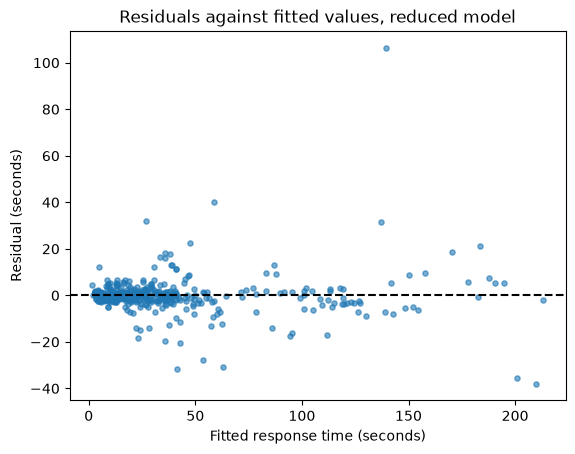

In [17]:
# residuals are what the chosen model failed to explain
reduced_model_residuals = reduced_model.resid
# fitted values are what it predicted for each run
reduced_model_fitted_values = reduced_model.fittedvalues

plt.scatter(reduced_model_fitted_values, reduced_model_residuals, s=14, alpha=0.6)
# reference line at zero, since residuals should scatter around it
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel('Fitted response time (seconds)')
plt.ylabel('Residual (seconds)')
plt.title('Residuals against fitted values, reduced model')
plt.show()

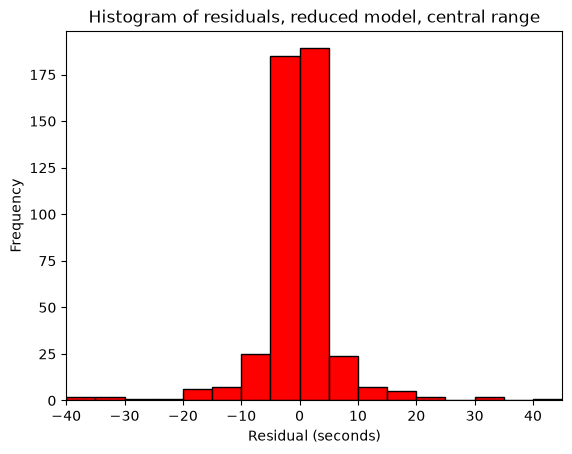

In [57]:
# bin edges every 5 seconds
residual_bin_edges = list(range(-40, 50, 5))

# histogram checks whether the residuals are roughly bell-shaped
plt.hist(reduced_model_residuals, residual_bin_edges, color='red', edgecolor='k')
plt.xlabel('Residual (seconds)')
plt.ylabel('Frequency')
plt.xlim(-40, 45)
plt.title('Histogram of residuals, reduced model, central range')
plt.show()

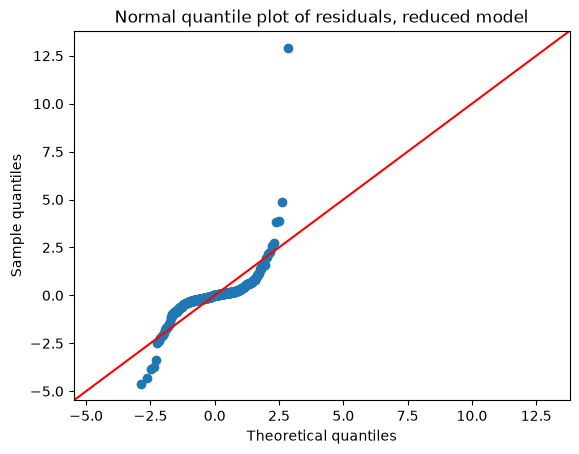

In [58]:
# the normal quantile plot
quantile_plot_figure = sm.graphics.qqplot(reduced_model_residuals, dist=stats.norm, line='45', fit=True)
plt.xlabel('Theoretical quantiles')
plt.ylabel('Sample quantiles')
plt.title('Normal quantile plot of residuals, reduced model')
plt.show()

In [20]:
# split the fitted values into quarters to measure the spread
fitted_value_quarters = pd.qcut(reduced_model_fitted_values, 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
residual_spread_by_quarter = reduced_model_residuals.groupby(fitted_value_quarters, observed=True).std()
print('Residual standard deviation by quarter of fitted value:')
print(residual_spread_by_quarter.round(2))

# skewness measures how far the residuals are from symmetric
residual_skewness = round(float(reduced_model_residuals.skew()), 4)
print('Residual skewness:', residual_skewness)

Residual standard deviation by quarter of fitted value:
Q1     2.21
Q2     2.79
Q3     6.41
Q4    14.81
dtype: float64
Residual skewness: 4.5194


### 12.1 Diagnostic Results

Both normal-model assumptions fail, but for different reasons.

**Constant variance.** The residual standard deviation rose across quarters of the fitted values, from 2.21 seconds in the lowest to 2.79, 6.41 and 14.81 in the highest, and the residuals-versus-fitted plot shows the same funnel opening to the right. The normal GLM assumes one standard deviation at every fitted value, and these data do not have one.

**Normality.** Residual skewness was 4.52, but this comes from one observation rather than a tail. The residuals are nearly symmetric out to plus or minus 30 seconds, and the most positive residual, 106.45 seconds, belongs to run 369, the slowest run in the log (Section 13).

Because the spread grows with the mean, the coefficients remain unbiased, but the standard errors, confidence intervals and P-values understate uncertainty where response times are large. A gamma GLM, whose variance function allows the variability of the response to grow with its mean, is one remedy; Candidate Model 4 (Section 15) takes the log-transform route.

---
## 13. Influential Observations

In [63]:
# get_influence holds the diagnostics for influential observations
reduced_model_influence = reduced_model.get_influence()
# cooks_distance returns a tuple; the first element is the distances
reduced_model_cooks_distances = pd.Series(
    reduced_model_influence.cooks_distance[0],
    index=successful_runs.index)
largest_cooks_distance = round(reduced_model_cooks_distances.max(), 4)
most_influential_run = reduced_model_cooks_distances.idxmax()
print('Largest Cook distance:', largest_cooks_distance)
print('Run index with that distance:', most_influential_run)
print('Most Influential Run'.center(80) + '\n')
print(successful_runs.loc[most_influential_run,
                          ['model', 'input_type', 'how_to_start',
                           'output_characters',
                           'model_time_seconds']])

Largest Cook distance: 1.3091
Run index with that distance: 369
                              Most Influential Run                              

model                           gemma-3-12b-it
input_type                        Text + Image
how_to_start          Telegram message trigger
output_characters                         3398
model_time_seconds                       246.0
Name: 369, dtype: object


/opt/anaconda3/lib/python3.14/site-packages/statsmodels/stats/outliers_influence.py:847: RuntimeWarning: invalid value encountered in sqrt
  return self.resid / sigma / np.sqrt(1 - hii)


In [65]:
# Get influence diagnostics
reduced_model_influence = reduced_model.get_influence()

# Check leverage values
leverage = reduced_model_influence.hat_matrix_diag

print("Maximum leverage:", leverage.max())
print("Minimum leverage:", leverage.min())

# Find observations with extremely high leverage
print("High leverage positions:")
print(np.where(leverage >= 0.99)[0])
diagnostics = pd.DataFrame({
    'leverage': reduced_model_influence.hat_matrix_diag,
    'cooks_distance': reduced_model_influence.cooks_distance[0]
}, index=reduced_model.model.data.row_labels)

print(
    diagnostics.sort_values(
        'leverage',
        ascending=False
    ).head(10)
)

Maximum leverage: 1.0000000000000209
Minimum leverage: 0.011093251878333349
High leverage positions:
[220]
     leverage  cooks_distance
304  1.000000             NaN
348  0.504338    1.785411e-03
4    0.504338    1.785411e-03
8    0.500126    3.135993e-07
352  0.500126    3.135993e-07
306  0.362535    1.897719e-02
305  0.357031    2.327644e-02
307  0.350015    7.962587e-02
0    0.276822    1.213727e-03
2    0.263826    5.065483e-05


/opt/anaconda3/lib/python3.14/site-packages/statsmodels/stats/outliers_influence.py:847: RuntimeWarning: invalid value encountered in sqrt
  return self.resid / sigma / np.sqrt(1 - hii)


### 13.1 Is the Largest Cook's Distance a Problem?

Cook's distance measures how much the whole fitted model shifts when
one case is deleted, so a case earns a large value either by sitting
far from the other responses or by being the only run of its kind.

The refit below distinguishes a case that matters from one that merely
stands out. If the rate and the fit barely move, the conclusions do not
rest on that single run.

In [66]:
# Diagnostic - Legitimate but extremely rare case?
# refit without that run
runs_without_influential = successful_runs.loc[successful_runs.index != most_influential_run]
model_without_influential = smf.ols(
    formula='model_time_seconds ~ C(model) + C(input_type)'
            ' + C(how_to_start) + output_characters'
            ' + input_characters'
            ' + C(model):output_characters',
    data=runs_without_influential).fit()

# compare the baseline slope and the fit, with and without that run
slope_with_run = round(reduced_model.params['output_characters'], 4)
slope_without_run = round(model_without_influential.params['output_characters'], 4)
print('Baseline slope with the run:', slope_with_run)
print('Baseline slope without the run:', slope_without_run)
print('Adjusted R-squared with the run:',
      round(reduced_model.rsquared_adj, 4))
print('Adjusted R-squared without the run:',
      round(model_without_influential.rsquared_adj, 4))
print(successful_runs.loc[304])

Baseline slope with the run: 0.0303
Baseline slope without the run: 0.0299
Adjusted R-squared with the run: 0.9572
Adjusted R-squared without the run: 0.9737
chat_id                                                              1475432104
test_id                                                                       1
scenario_name                                              Text Input - Model A
scenario_purpose              Test response and processing time for text-onl...
how_to_start                  Trigger n8n via webhook or Telegram bot with p...
input_type                                                            Text Only
model                                                             minicpm-o-2_6
image_input                                                                 ...
text_input                    /promptText create an article based on this in...
model_output                  Title: International Workshop on "Nanotechnolo...
workflow_name                             

### 13.2 Influential Observation Results

The largest Cook's distance was by gemma-3-12b-it call on a Text + Image request through the Telegram message trigger, which produced 3,398 characters in 246 seconds. That is the slowest run in the entire log.

Refitting without it moved the baseline rate only from 0.0303 to 0.0299 seconds per character, while adjusted R-squared rose from 0.9572 to 0.9737. The rate barely moves, so the conclusions do not rest on this single run.

---
## 14. Per-Model Generation Rates

Each interaction coefficient is the **difference** between a model's slope and the baseline slope, so each model's own rate is the baseline plus its adjustment.

The reduced model's rates are compared against the focused model's. If adding nine other predictors barely moves them, the rates are a property of the models rather than of one specification.

In [53]:
# the baseline model's slope on answer length, reduced model
reduced_model_baseline_rate = reduced_model.params['output_characters']
# the same slope from the focused model, for comparison
focused_model_baseline_rate = focused_interaction_model.params['output_characters']
print('Seconds per character, baseline model')
print('  reduced model:', round(reduced_model_baseline_rate, 4))
print('  focused model:', round(focused_model_baseline_rate, 4))

# each other model's rate is the baseline plus its own adjustment
for model_name in ['minicpm-o-2_6', 'pixtral-12b',
                   'qwen2-vl-7b-instruct']:
    # build the coefficient label
    coefficient_label = ('C(model)[T.' + model_name + ']:output_characters')
    reduced_model_rate = round(reduced_model_baseline_rate + reduced_model.params[coefficient_label], 4)
    focused_model_rate = round(focused_model_baseline_rate + focused_interaction_model.params[coefficient_label], 4)
    print('Seconds per character,', model_name)
    print('  reduced model:', reduced_model_rate)
    print('  focused model:', focused_model_rate)

Seconds per character, baseline model
  reduced model: 0.0303
  focused model: 0.0302
Seconds per character, minicpm-o-2_6
  reduced model: 0.0107
  focused model: 0.011
Seconds per character, pixtral-12b
  reduced model: 0.0263
  focused model: 0.0261
Seconds per character, qwen2-vl-7b-instruct
  reduced model: 0.0131
  focused model: 0.013


### 14.1 Per-Model Generation Rate Results

The interaction coefficient is the **difference** between a group's
rate and the baseline rate, so each model's own rate is the baseline
plus its adjustment.

| Model | Candidate Model 3 | Focused model |
| --- | --- | --- |
| gemma-3-12b-it (baseline) | 0.0303 | 0.0302 |
| pixtral-12b | 0.0263 | 0.0261 |
| qwen2-vl-7b-instruct | 0.0131 | 0.0130 |
| minicpm-o-2_6 | 0.0107 | 0.0110 |

Holding the other predictors constant, the four models generate text at
0.0107 to 0.0303 seconds per character. The slowest model takes about 2.8 times as long per character as the
fastest.

Adding nine further predictors to the focused specification barely moves these rates.

---
## 15. Candidate Model 4: Log-Transformed Response

The diagnostics on Candidate Model 3 found the residual standard
deviation rising from 2.21 seconds to 14.81 across quarters of the
fitted values, and residual skewness of 4.52. Both are symptoms of a
response whose spread grows with its mean.

Taking the logarithm compresses the upper tail: a run at 246 seconds
and a run at 24.6 seconds sit the same distance apart on a log scale as
24.6 and 2.46 do. If the spread of response time is proportional to its
level, that compression should flatten it.

The predictor structure is identical to Candidate Model 3, so the only
difference between the two models is the scale of the response.

In [54]:
# reduced structure with log response, Appendix B7.1.1 In [3]
log_response_model = smf.ols(
    formula='np.log(model_time_seconds) ~ C(model) + C(input_type)'
            ' + C(how_to_start) + output_characters'
            ' + input_characters'
            ' + C(model):output_characters',
    data=successful_runs).fit()
print('Parameters estimated:', len(log_response_model.params))
print('Log Response Model'.center(80) + '\n')
print(log_response_model.summary())

Parameters estimated: 22
                               Log Response Model                               

                                OLS Regression Results                                
Dep. Variable:     np.log(model_time_seconds)   R-squared:                       0.893
Model:                                    OLS   Adj. R-squared:                  0.888
Method:                         Least Squares   F-statistic:                     173.5
Date:                        Mon, 12 Oct 2026   Prob (F-statistic):          3.23e-197
Time:                                08:45:40   Log-Likelihood:                -145.75
No. Observations:                         460   AIC:                             335.5
Df Residuals:                             438   BIC:                             426.4
Df Model:                                  21                                         
Covariance Type:                    nonrobust                                         
                       

In [25]:
# typ=2 gives one F test per variable, adjusted for the others
log_response_term_tests = sm.stats.anova_lm(log_response_model, typ=2)
print(log_response_term_tests.round(4))

                              sum_sq     df          F  PR(>F)
C(model)                     63.4805    3.0   182.6024  0.0000
C(input_type)                 2.5006    3.0     7.1931  0.0001
C(how_to_start)               5.0424   10.0     4.3514  0.0000
output_characters           176.9694    1.0  1527.1639  0.0000
C(model):output_characters   20.5116    3.0    59.0019  0.0000
input_characters              1.9612    1.0    16.9240  0.0000
Residual                     50.7559  438.0        NaN     NaN


### 15.1 Diagnostics on the Log-Transformed Model

The same three checks run on Candidate Model 3 are repeated here, so
the two models are judged on identical evidence.

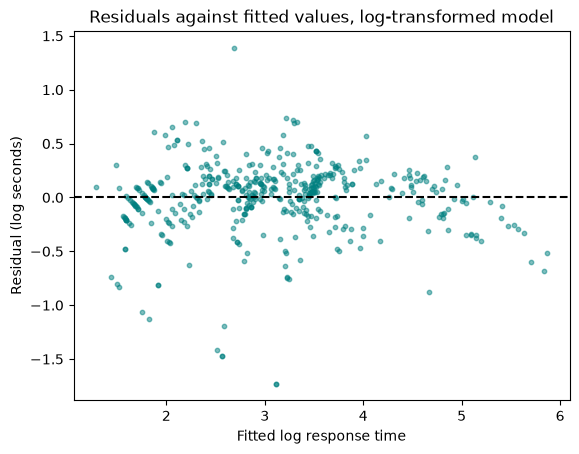

In [55]:
# residuals and fitted values on the log scale
log_model_residuals = log_response_model.resid
log_model_fitted_values = log_response_model.fittedvalues

plt.scatter(log_model_fitted_values, log_model_residuals, s=10, alpha=0.5, color='teal')
plt.xlabel('Fitted log response time')
plt.ylabel('Residual (log seconds)')
# reference line at zero, since residuals should scatter around it
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Residuals against fitted values, log-transformed model')
plt.show()

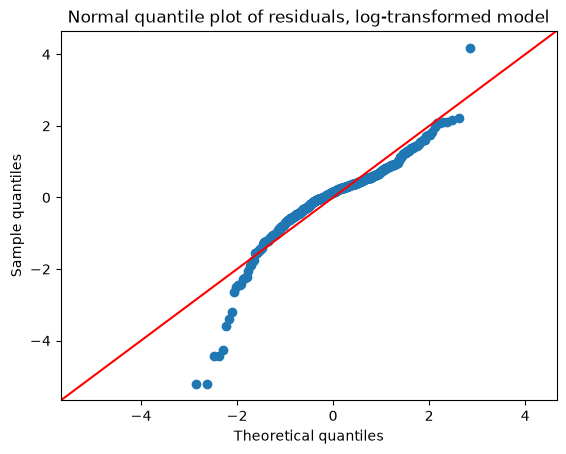

In [27]:
# the normal quantile plot
log_quantile_plot_figure = sm.graphics.qqplot(
    log_model_residuals, dist=stats.norm, line='45', fit=True)
plt.xlabel('Theoretical quantiles')
plt.ylabel('Sample quantiles')
plt.title('Normal quantile plot of residuals, log-transformed model')
plt.show()

In [28]:
# split the fitted values into quarters to measure the spread
log_fitted_value_quarters = pd.qcut(log_model_fitted_values, 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
log_residual_spread_by_quarter = log_model_residuals.groupby(log_fitted_value_quarters, observed=True).std()
print('Residual standard deviation by quarter of fitted value:')
print(log_residual_spread_by_quarter.round(3))

# skewness measures how far the residuals are from symmetric
log_residual_skewness = round(float(log_model_residuals.skew()), 4)
print('Residual skewness:', log_residual_skewness)

Residual standard deviation by quarter of fitted value:
Q1    0.331
Q2    0.357
Q3    0.367
Q4    0.264
dtype: float64
Residual skewness: -1.382


### 15.2 Rates as Percentage Increases

The calculation below reports each model's rate as the percentage increase in response time per 100 additional characters.

In [61]:
# the baseline model's slope on answer length, log scale
log_baseline_slope = log_response_model.params['output_characters']
# exp turns an additive log effect into a multiplier on seconds
log_baseline_multiplier = np.exp(log_baseline_slope * 100)
# expressed as a percentage increase per 100 characters
log_baseline_percent = round((log_baseline_multiplier - 1) * 100, 2)
print('Percent increase per 100 characters, baseline model')
print('  gemma-3-12b-it:', log_baseline_percent)

# each other model's slope is the baseline plus its own adjustment
for model_name in ['minicpm-o-2_6', 'pixtral-12b', 'qwen2-vl-7b-instruct']:
    # build the coefficient label exactly as the summary prints it
    log_coefficient_label = ('C(model)[T.' + model_name + ']:output_characters')
    log_model_slope = (log_baseline_slope + log_response_model.params[log_coefficient_label])
    log_model_multiplier = np.exp(log_model_slope * 100)
    log_model_percent = round((log_model_multiplier - 1) * 100, 2)
    print('Percent increase per 100 characters,', model_name, ':', log_model_percent)

Percent increase per 100 characters, baseline model
  gemma-3-12b-it: 4.18
Percent increase per 100 characters, minicpm-o-2_6 : 7.29
Percent increase per 100 characters, pixtral-12b : 6.3
Percent increase per 100 characters, qwen2-vl-7b-instruct : 11.33


### 15.3 Candidate Model 4 Results

The log-transformed model was statistically significant overall,
F(21, 438) = 173.53, p < .001, and explained approximately 89.3% of the
variation in log response time (R-squared = 0.8927; adjusted
R-squared = 0.8876) using the same 22 parameters as Candidate Model 3.
Every term remained significant at p < 0.001 except input type, at
p = 0.0001, and the interaction remained strongly supported,
F(3, 438) = 59.00, p < .001.

**The transformation repairs constant variance.**

| Quarter of fitted values | Candidate Model 3 | Candidate Model 4 |
| --- | --- | --- |
| Q1 | 2.212 | 0.331 |
| Q2 | 2.790 | 0.357 |
| Q3 | 6.414 | 0.367 |
| Q4 | 14.807 | 0.264 |
| Highest divided by lowest | 6.70 | 0.80 |

**The cost.** On the log scale the slope is a proportional change, so the per-model rates
convert to percentage increases per 100 characters:

| Model | Seconds per character (Model 3) | Percent per 100 characters (Model 4) |
| --- | --- | --- |
| gemma-3-12b-it | 0.0303 | 4.18 |
| pixtral-12b | 0.0263 | 6.30 |
| qwen2-vl-7b-instruct | 0.0131 | 11.33 |
| minicpm-o-2_6 | 0.0107 | 7.29 |

**The ordering.** Gemma is the slowest model in absolute seconds, so each additional character adds a small fraction of an already-large time. Qwen is among the fastest, so each additional character adds a large fraction of a small time. Candidate Model 3 answers how many seconds a longer answer costs; Candidate Model 4 answers what percentage a longer answer adds.

---
## 16. Results

Of the 600 logged requests, 460 completed successfully and form the
analysis sample. Each of the four models contributed 115 runs.

### Hypothesis tests

| Hypothesis | Test | Statistic | Decision |
| --- | --- | --- | --- |
| Main effects | Global F, Candidate Model 3 | F(21, 438) = 490.39, p < .001 | H0 rejected |
| Interaction | Nested F, Model 1 against Model 2 | F(3, 433) = 136.18, p < .001 | H0 rejected |
| Reduction | Nested F, Model 3 against Model 2 | F(5, 433) = 0.2284, p = .950 | H0 not rejected |

All three hypotheses stated at the top of the notebook are resolved by
these tests. Response time is associated with the request
characteristics, the association with answer length differs across
models, and the five terms dropped from the wide model contribute
nothing.

### Candidate models

The wide main-effects model explained 92.1% of the variation in
response time with 24 parameters (adjusted R-squared = 0.917). Adding
the model by answer-length interaction raised this to 95.9% with 27
parameters (adjusted R-squared = 0.9569). Removing the five
non-contributing terms left 95.9% with 22 parameters and the best
adjusted R-squared of the five specifications, 0.9572, and the lowest
AIC, 3289.50.

Candidate Model 4 refitted that same structure with the logarithm of
response time. It was significant overall, F(21, 438) = 173.53,
p < .001. Its fit statistics are not comparable with the others because
the response variable differs, so it is judged on diagnostics instead.

The wide main-effects model, with 24 parameters, was beaten by the
focused model with the interaction and only 11 parameters (adjusted
R-squared 0.9167 against 0.9487; AIC 3597.95 against 3362.97).

### Which characteristics mattered

Five earned their place: model choice, input type, trigger type, answer
length and request length. Answer length dominated, with a sum of
squares roughly nine times that of model choice.

Five did not: workflow name (p = .888), whether an image was attached
(p = .714), average CPU load (p = .885), average GPU load (p = .445)
and average memory (p = .636). The three resource metrics are the most
informative negative result, because they show that response time here
is governed by how much text is produced rather than by machine
contention.

### Per-model generation rates

Holding the other predictors constant, the estimated rates were 0.0303
seconds per character for gemma-3-12b-it, 0.0263 for pixtral-12b,
0.0131 for qwen2-vl-7b-instruct and 0.0107 for minicpm-o-2_6, a range
of nearly threefold. The focused model gives 0.0302, 0.0261, 0.0130 and
0.0110, so the rates are a property of the models rather than of one
specification.

---
## 17. Reference

Agresti, A., & Kateri, M. (2022). *Foundations of statistics for data
scientists: With R and Python*. Chapman & Hall/CRC. Python Web
Appendix, Sections B6.1 (pp. 39-40), B6.2 (pp. 40-41), B6.3
(pp. 41-45), B6.5.2-B6.5.3 (pp. 50-51), and B7.1-B7.1.1 (pp. 55-57), the last of which supplies
the log-transformed linear model used in Candidate Model 4.